In [1]:
import numpy as np
import matplotlib.pyplot as plt
import csv
import pandas as pd
import scipy
from pathlib import Path

import sys
sys.path.insert(0,"VNA_analysis/")
from VNA_data import VNA_data

sys.path.insert(0, "/home/jupyter-ludovico/stout")
from stout.services.inventory.service import InventoryService

Inventory schemas path: /home/jupyter-ludovico/stout/schemas/inventory_v1.json
Measurements schemas path: /home/jupyter-ludovico/stout/schemas/measurements_v1.json


In [2]:
def get_item_lab_charact_datapath(dB_dirpath,item,meas_type,key):
    """
    Returns the path to the lab characterization database of the item.
    Input:
        dB_dirpath (str): general path to the database (usually 'mnt/data/POLOCALC/lab')
        item (dB object): database item object present in the paylaod
        meas_type (str): item measurement type
        key (str): key to be find in the files to get the correct characterization file
    """
    try:
        item_spec = item["specifications"]
        band_mask = ["band" in p for p in list(item_spec.keys())]
        band_key = np.asarray(list(item_spec.keys()))[band_mask][0]
        item_charact_path = dB_dirpath / item_spec[band_key] / item["category"] / item["name"] / meas_type

        item_charact_file = sorted(p for p in item_charact_path.iterdir() if p.is_file() and key in p.name.lower())[0]

    except Exception as e:
        raise ValueError(f"Error in loading the lab characterization file for {item['name']}: \n{e}")
        
    return item_charact_file

# Run everything from Jupyter Notebook:

In [3]:
inv_service = InventoryService()

item = inv_service.get_item_by_id(item_id="0f7185b2-ab73-42a2-a3f2-392bfdaba945")
item

2026-08-14 17:45:15 - stout - WARNING - [authenticated_user] - Cannot write to log directory /mnt/data/POLOCALC/logs: [Errno 13] Permission denied: '/mnt/data/POLOCALC/logs/stout.log'. Using console logging only.
2026-08-14 17:45:15 - stout - INFO - [authenticated_user] - Centralized logging system initialized


{'category': 'attenuator',
 'serial_number': '11103-01',
 'specifications': {'model': 'STA-30-10-F1-C-1.2',
  'manufacturer': 'Eravant',
  'input_band': 'WR10',
  'attenuation': 30.0},
 'name': 'ATT_002',
 'item_id': '0f7185b2-ab73-42a2-a3f2-392bfdaba945',
 'created_at': datetime.datetime(2025, 11, 30, 13, 41, 50, 650495),
 'updated_at': datetime.datetime(2026, 7, 29, 14, 5, 53, 832609)}

In [4]:
datapath = get_item_lab_charact_datapath(dB_dirpath = Path("/mnt/data/POLOCALC/lab"),
                                         item=item,meas_type='attenuation',key="raw.s2p")
datapath

PosixPath('/mnt/data/POLOCALC/lab/WR10/attenuator/ATT_002/attenuation/20260617_140000_raw.s2p')

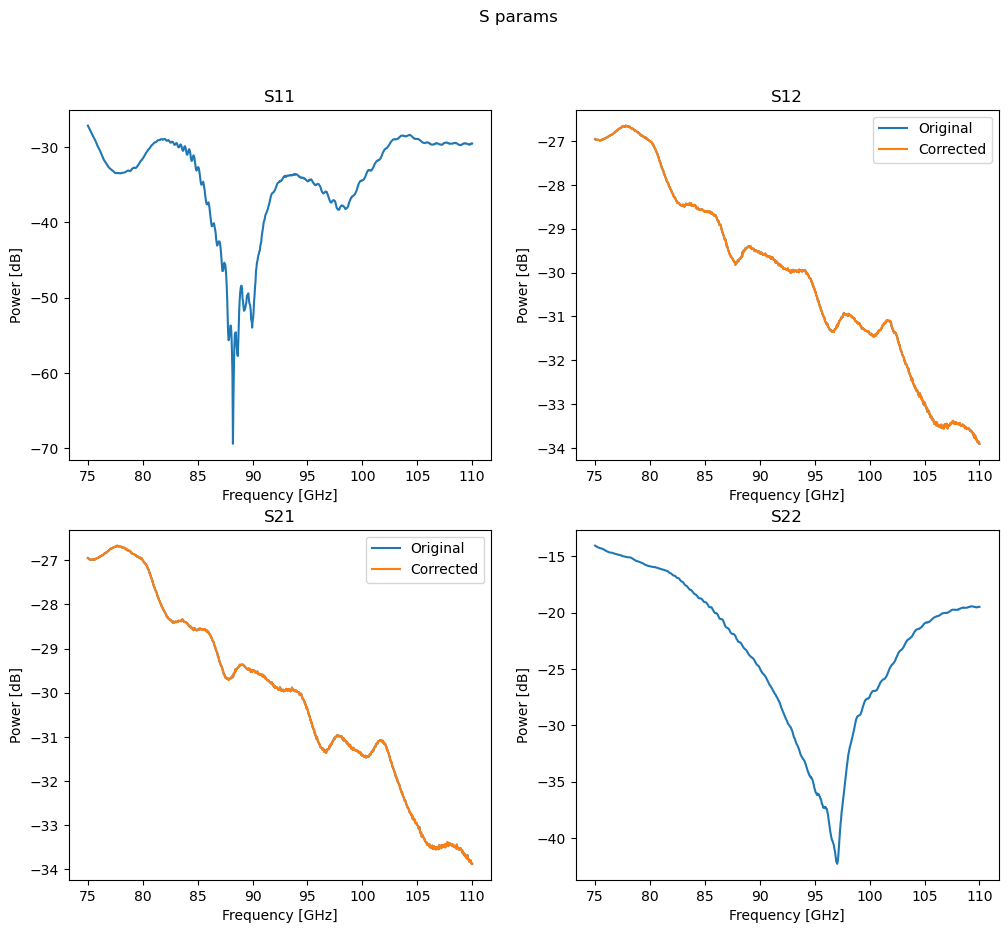

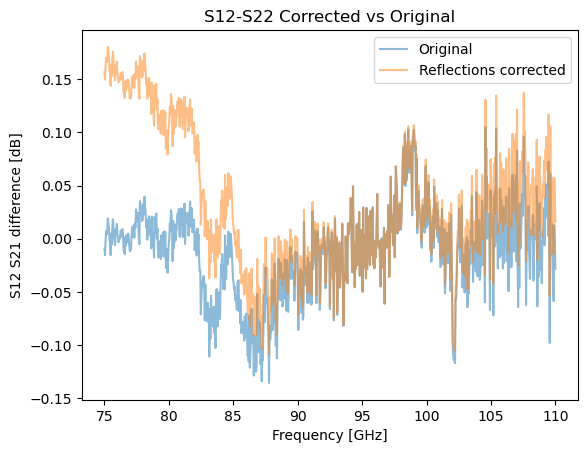

In [5]:
item_meas_VNA = VNA_data(datapath)
item_meas_VNA.correct_S_params()

item_meas_VNA.plot_S_params()

In [6]:
analysis_freqs = np.asarray([84,87,90,93,96,99,102])
freq_interval = 0.1

item_meas_VNA.run_single_freqs(interest_freqs=analysis_freqs,method="original",freq_interval=freq_interval)

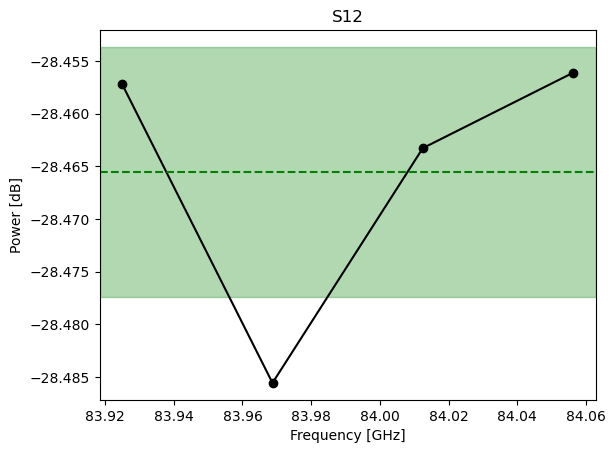

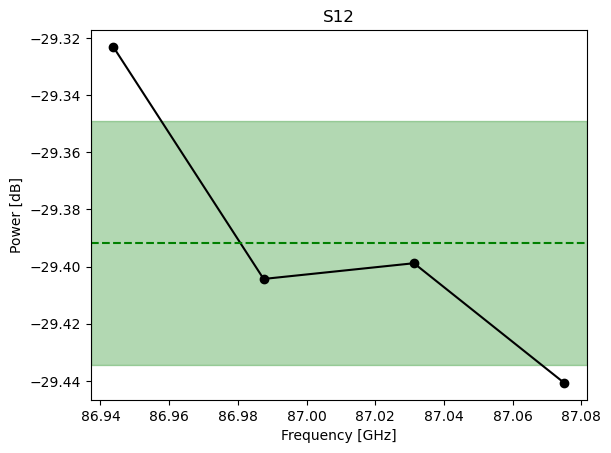

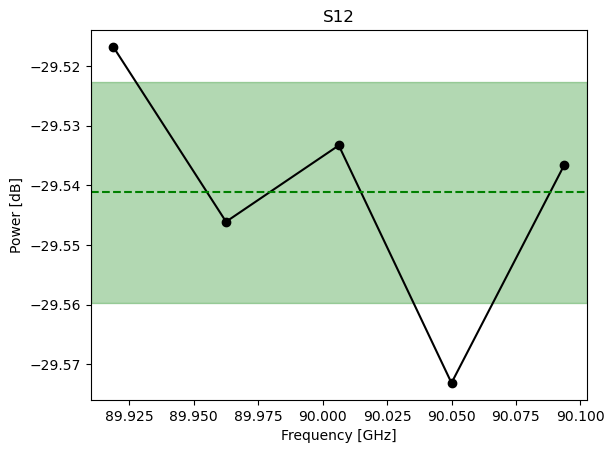

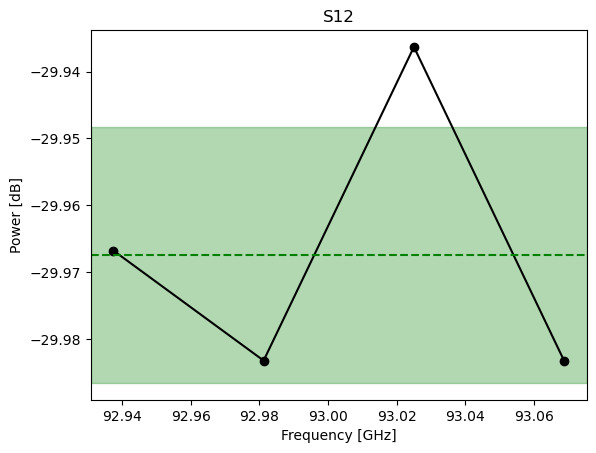

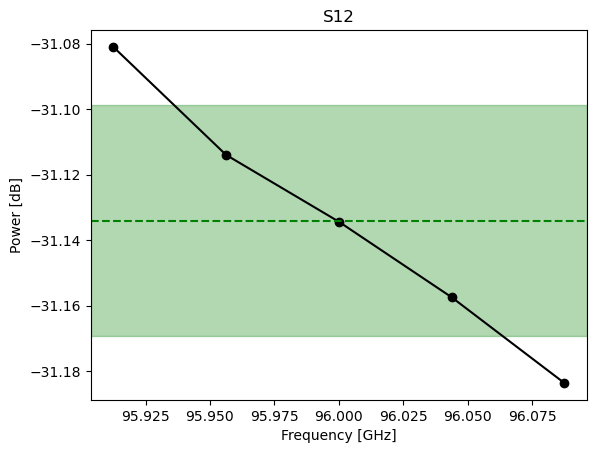

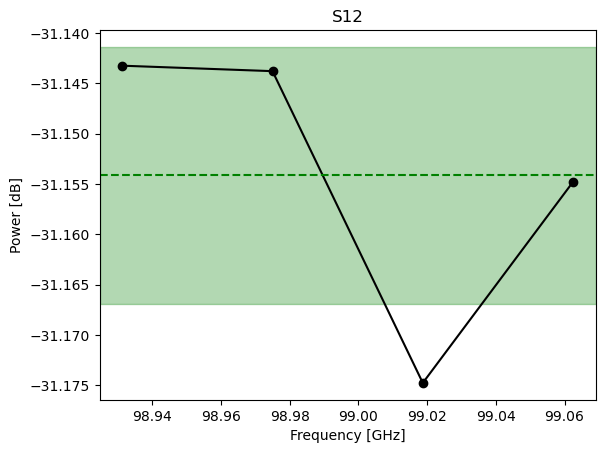

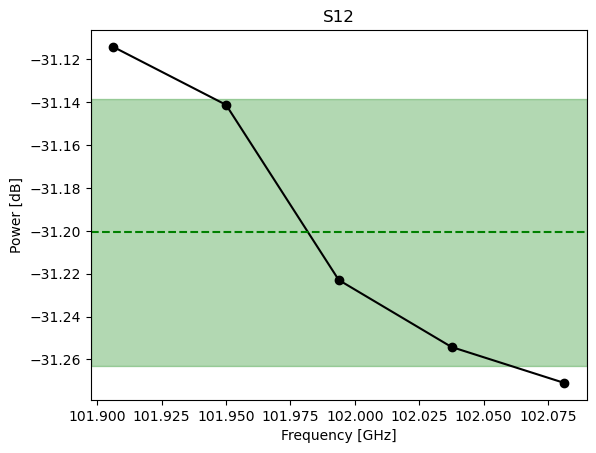

In [7]:
for f in item_meas_VNA.single_freqs_df["Frequency"].values:
    
    freq_mask = (item_meas_VNA.freq>f-freq_interval) & (item_meas_VNA.freq<f+freq_interval)
    plt.plot(item_meas_VNA.freq[freq_mask],item_meas_VNA.S12[freq_mask] ,ls="-",marker="o",color="black")

    avg = item_meas_VNA.single_freqs_df["S12 avg [dB]"][item_meas_VNA.single_freqs_df["Frequency"]==f].values[0]
    std = item_meas_VNA.single_freqs_df["S12 std [dB]"][item_meas_VNA.single_freqs_df["Frequency"]==f].values[0]
    
    plt.axhline(avg,color="green",ls="--")
    plt.axhspan(avg-std,avg+std,color="green",alpha=0.3)

    plt.title("S12")
    plt.xlabel("Frequency [GHz]")
    plt.ylabel("Power [dB]")
    plt.show()

<ErrorbarContainer object of 3 artists>

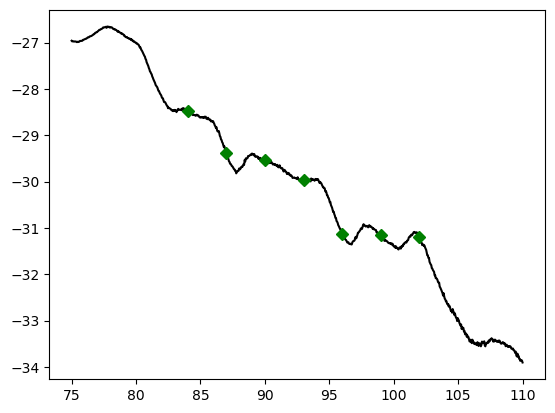

In [8]:
plt.plot(item_meas_VNA.freq,item_meas_VNA.S12,color="black")
plt.errorbar(item_meas_VNA.single_freqs_df["Frequency"],item_meas_VNA.single_freqs_df["S12 avg [dB]"].values,
             yerr=item_meas_VNA.single_freqs_df["S12 std [dB]"],
             ls="",marker="D",color="green",)

# Use the dedicated python script:

In [9]:
import os

outpath = f"test_outpath/{item["name"]}/"

os.system(f"python3 run_analysis.py -d '{datapath}' -o '{outpath}'")

Figure(1200x1000)
Figure(640x480)
ATT_002
Figure(1500x1200)
Figure(640x480)


0